**Aluno:** João Paulo Gomes de Oliveira

---

# Primeiro modelo preditivo para manutenção

## Objetivo da aula

Neste notebook, construiremos um **classificador supervisionado** para responder à pergunta:

> Com base nas condições observadas da máquina, o modelo consegue identificar uma falha?

Não basta treinar um algoritmo. Precisamos percorrer um pipeline completo e saber o que acontece em cada etapa:

1. **Carregar os dados** — trazer o arquivo CSV para o Python.
2. **Conhecer os dados** — entender linhas, colunas, tipos e variável de interesse.
3. **Preparar os dados** — renomear colunas, tratar valores extremos e construir a potência mecânica.
4. **Definir o problema** — separar os atributos de entrada (`X`) do resultado que queremos prever (`y`).
5. **Separar treino e teste** — ensinar o modelo com uma parte dos dados e avaliá-lo em observações não usadas no treino.
6. **Treinar o modelo** — ajustar um classificador LightGBM. Outros classificadores possíveis incluem: *Logistic regression*, *Decision Tree*, *Random Forest*, *Support Vector Machine (SVM)*, *k-Nearest Neighbours (KNN)* e *Neural Networks*.
7. **Gerar previsões** — obter probabilidades e classes previstas.
8. **Avaliar e decidir** — interpretar a matriz de confusão e métricas adequadas a um evento raro.

### Como executar no JupyterLab

- Execute uma célula por vez com **Shift + Enter**.
- O número entre colchetes à esquerda indica que a célula foi executada.
- Se aparecer `NameError`, normalmente uma célula anterior ainda não foi executada.
- Para recomeçar de forma limpa, use **Kernel → Restart Kernel and Run All Cells**.

Ao final, o objetivo não é apenas obter uma boa pontuação, mas decidir se o modelo é suficientemente seguro para apoiar a manutenção.

In [1]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="darkgrid", palette="rainbow")
%matplotlib inline

import methods

# https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset

# BUGFIX: o caminho original ("../data/ai4i2020/ai4i2020.csv") nao existe neste projeto.
# O CSV foi adicionado dentro desta propria pasta.
ai4i2020_df = pd.read_csv("ai4i2020.csv", encoding="utf-8-sig")
    

## 1. Carregamento e inspeção inicial

A biblioteca `pandas` lê o arquivo CSV e o representa como um **DataFrame**, uma tabela com linhas e colunas.

Antes de modelar, confirme se os dados foram carregados corretamente:

- `head()` mostra as cinco primeiras linhas;
- `info()` mostra quantidade de registros, nomes das colunas, tipos e valores ausentes.

**Perguntas para observar:** o que representa uma linha? Quantas variáveis existem? Qual coluna indica a ocorrência de falha?

In [2]:
ai4i2020_df.head()


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
ai4i2020_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [4]:
renamed_df = ai4i2020_df.rename(columns={
    'Air temperature [K]': 'air_temp_k',
    'Process temperature [K]': 'process_temp_k',
    'Rotational speed [rpm]': 'speed_rpm',
    'Torque [Nm]': 'torque_nm',
    'Tool wear [min]': 'tool_wear_min',
    'Machine failure': 'failures',
    'TWF': 'tool_wear_f',
    'HDF': 'heat_diss_f',
    'PWF': 'power_f',
    'OSF': 'overstrain_f',
    'RNF': 'random_f',
})


In [5]:
renamed_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   UDI             10000 non-null  int64  
 1   Product ID      10000 non-null  str    
 2   Type            10000 non-null  str    
 3   air_temp_k      10000 non-null  float64
 4   process_temp_k  10000 non-null  float64
 5   speed_rpm       10000 non-null  int64  
 6   torque_nm       10000 non-null  float64
 7   tool_wear_min   10000 non-null  int64  
 8   failures        10000 non-null  int64  
 9   tool_wear_f     10000 non-null  int64  
 10  heat_diss_f     10000 non-null  int64  
 11  power_f         10000 non-null  int64  
 12  overstrain_f    10000 non-null  int64  
 13  random_f        10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
memory usage: 1.1 MB


## 2. Preparação dos dados

### 2.1 Identificação e tratamento de valores extremos

Um **outlier** é uma observação muito distante da maior parte dos dados. Ele pode representar erro de medição, condição operacional rara ou comportamento real da máquina. Portanto, não deve ser removido automaticamente.

Primeiro visualizamos separadamente a distribuição e o boxplot de `speed_rpm` e `torque_nm`, pois as duas variáveis possuem valores extremos e escalas diferentes. Em seguida, limitamos os outliers de ambas usando a média e o desvio-padrão. Este procedimento é chamado de *capping*: preserva a linha, mas substitui valores além dos limites pelo limite mais próximo.

Depois do tratamento, reconstruímos a potência mecânica usada na aula anterior:

$$
P = \tau \cdot \omega
  = \text{torque} \cdot \text{rotação} \cdot \frac{2\pi}{60}
$$

Essa etapa é um exemplo de **engenharia de atributos**: criar uma variável informativa a partir de conhecimento físico.

> **Nota metodológica**: neste primeiro contato, o tratamento é aplicado antes da divisão treino–teste para manter o percurso visual simples. Em um pipeline de produção, os limites devem ser aprendidos **somente no conjunto de treino** e depois aplicados ao teste, evitando vazamento de informação (*leakage*).

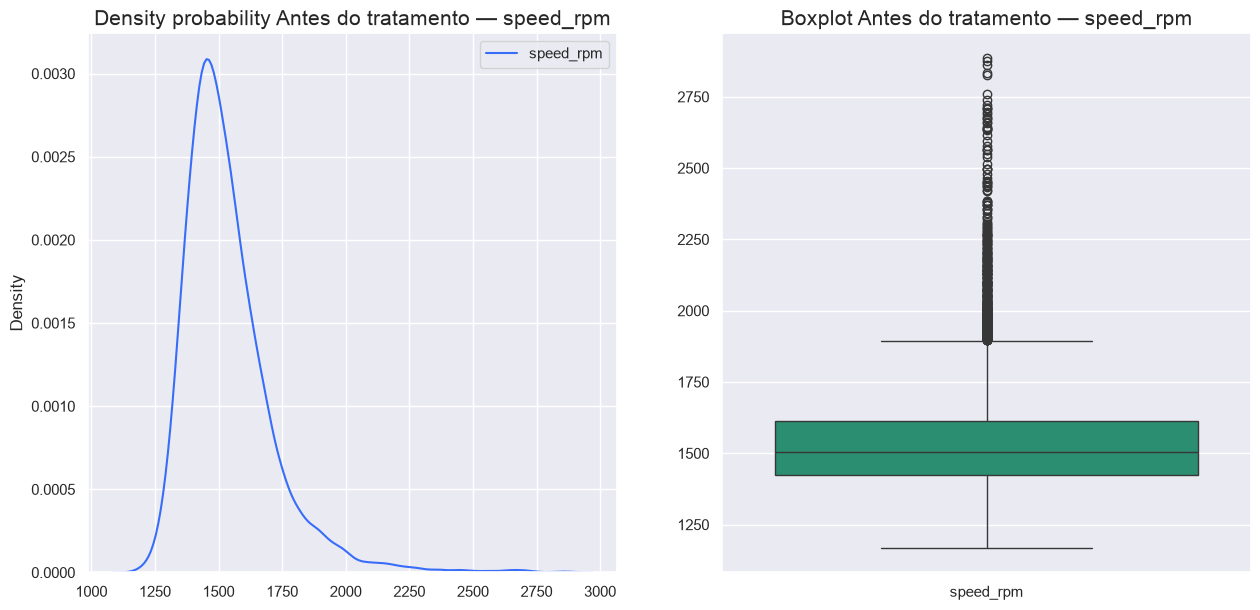

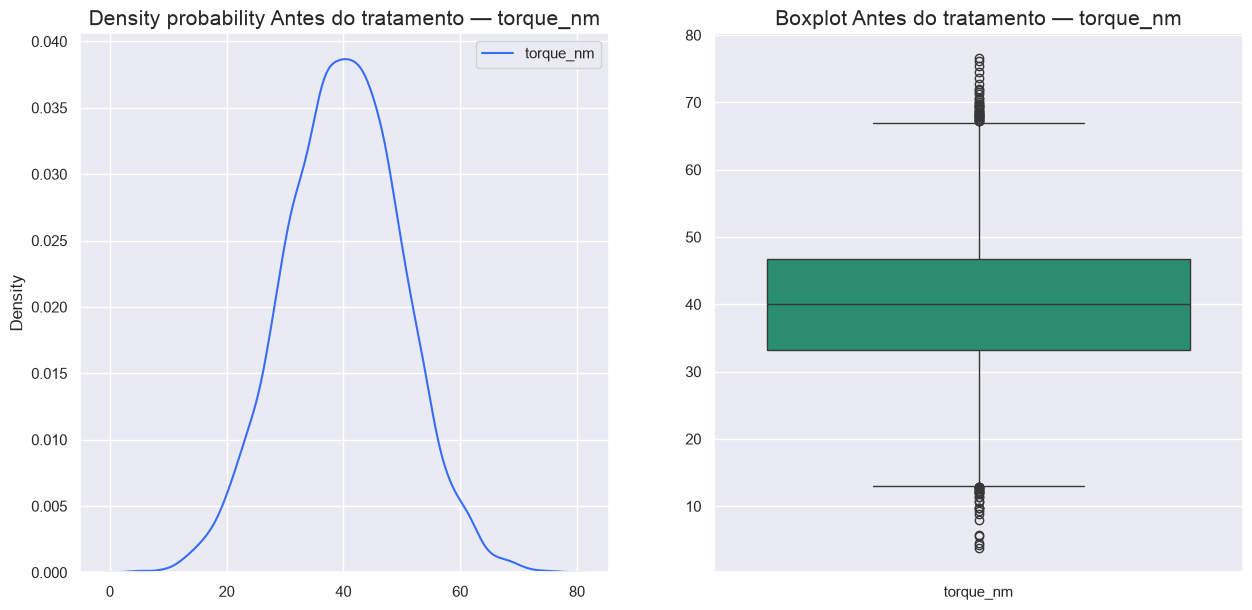

In [6]:
# As duas variáveis têm escalas diferentes; por isso, são mostradas em gráficos separados.
columns_with_outliers = ["speed_rpm", "torque_nm"]

for column in columns_with_outliers:
    methods.plot_outliers(
        f"Antes do tratamento — {column}",
        renamed_df,
        [column],
        plt,
        sns,
    )


### 2.2 Como funciona `treat_outliers()`

A função está definida no arquivo `methods.py`. Ela recebe o DataFrame, as colunas, um método para calcular limites e uma ação para os valores que ultrapassam esses limites.

Para cada coluna, a lógica é:

```python
# método STD
limite_inferior = média - fator × desvio_padrão
limite_superior = média + fator × desvio_padrão

# método IQR
IQR = terceiro_quartil - primeiro_quartil
limite_inferior = primeiro_quartil - fator × IQR
limite_superior = terceiro_quartil + fator × IQR
```

Depois, a função oferece dois tratamentos:

- `treatment="cap"`: substitui valores abaixo ou acima dos limites pelo respectivo limite;
- `treatment="remove"`: exclui toda a linha que contenha um valor fora dos limites.

> **Atualização**: a célula de código abaixo foi alterada de `method="STD"` para `method="IQR"`,
> `factor=1.5` (ou seja, 1,5 × IQR) — o restante desta seção mantém a discussão original sobre
> `STD` porque as vantagens/limitações comparadas entre os dois métodos continuam válidas como
> referência. O notebook `dashboard_sistema_falhas_IRQ_outlier.html` e
> `dashboard_sistema_falhas_IRQ_no-outlier.html` comparam lado a lado o efeito de tratar (IQR)
> ou não tratar os outliers no resultado final do modelo.

#### Escolha adotada neste notebook

Usamos `method="STD"`, `factor=1.5` e `treatment="cap"` em `speed_rpm` e `torque_nm`.

**Vantagens:**

- preserva todas as linhas, o que é útil quando falhas são raras;
- reduz a influência de valores muito extremos no treinamento;
- é simples de visualizar e explicar;
- mantém treino e avaliação com a mesma quantidade de observações.

**Limitações:**

- média e desvio-padrão são sensíveis aos próprios valores extremos;
- `1.5 × desvio-padrão` é um limite relativamente agressivo e não representa uma lei física;
- vários valores diferentes passam a ter exatamente o mesmo valor no limite;
- alterar rotação e torque também altera a potência calculada depois;
- um extremo válido pode ser evidência de degradação ou de uma falha e, portanto, não deveria ser apagado;
- neste exemplo didático, os limites são calculados antes do *split*. Em uso rigoroso, devem ser estimados **apenas no treino** e reutilizados no teste.

#### Outras possibilidades

- **Não tratar:** adequado quando os valores são fisicamente possíveis e o algoritmo é robusto. Árvores e ensembles costumam ser menos sensíveis à escala que modelos lineares.
- **Excluir a linha:** justificável para erro confirmado de aquisição, mas perigoso em eventos raros e quando remove justamente condições de falha.
- **Usar IQR:** não pressupõe distribuição aproximadamente normal e é mais robusto, embora seus limites continuem sendo estatísticos, não físicos.
- **Aplicar limites de engenharia:** usar faixa do sensor, envelope operacional, limites de projeto ou regras de plausibilidade. Geralmente é preferível quando esses limites são conhecidos e rastreáveis.
- **Transformar a variável:** logaritmo ou outra transformação pode reduzir assimetria, mas muda a interpretação e não corrige erro de sensor.
- **Usar métodos/modelos robustos:** escalonamento robusto, regressões robustas ou modelos baseados em árvores podem reduzir a necessidade de alterar os dados.
- **Criar um indicador:** manter o valor e adicionar uma coluna como `torque_extremo = 1`. Assim, o modelo pode aprender que a condição extrema tem significado.
- **Tratar como anomalia:** investigar o registro separadamente, especialmente quando o objetivo é detectar comportamento incomum.

#### Decisão de engenharia antes da decisão estatística

Antes de tratar um extremo, pergunte:

1. O valor é possível segundo a faixa e a resolução do sensor?
2. Está dentro do envelope operacional do equipamento?
3. Outros sensores ou registros confirmam essa condição?
4. O valor ocorre durante partida, transiente, mudança de regime ou outra fase específica?
5. Ele antecede ou coincide com uma falha?
6. A ação escolhida preserva a rastreabilidade do dado original?

A regra central é: **não tratar um valor apenas porque ele parece raro**. Primeiro determine se ele é erro, condição operacional válida ou sinal de degradação.

Limites estatísticos usados no capping (Q1 - 1,5×IQR, Q3 + 1,5×IQR):
speed_rpm      : [ 1139.50,  1895.50] —  418 registros;  35 deles com falha
torque_nm      : [   12.80,    67.20] —   69 registros;  62 deles com falha

Impacto conjunto: 459 registros terão ao menos um valor limitado; eles incluem 72 de 339 falhas.
Esses números devem ser avaliados antes de confirmar a decisão de engenharia.

Linhas restantes apos remocao: 9535 de 10000
Falhas restantes: 263 de 339


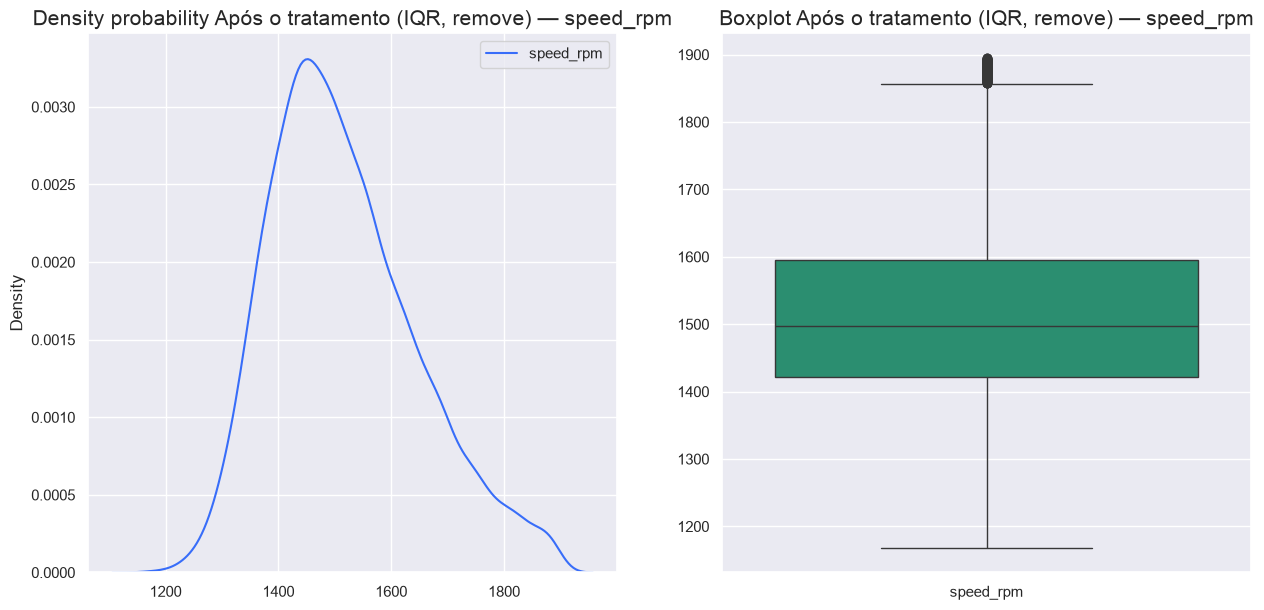

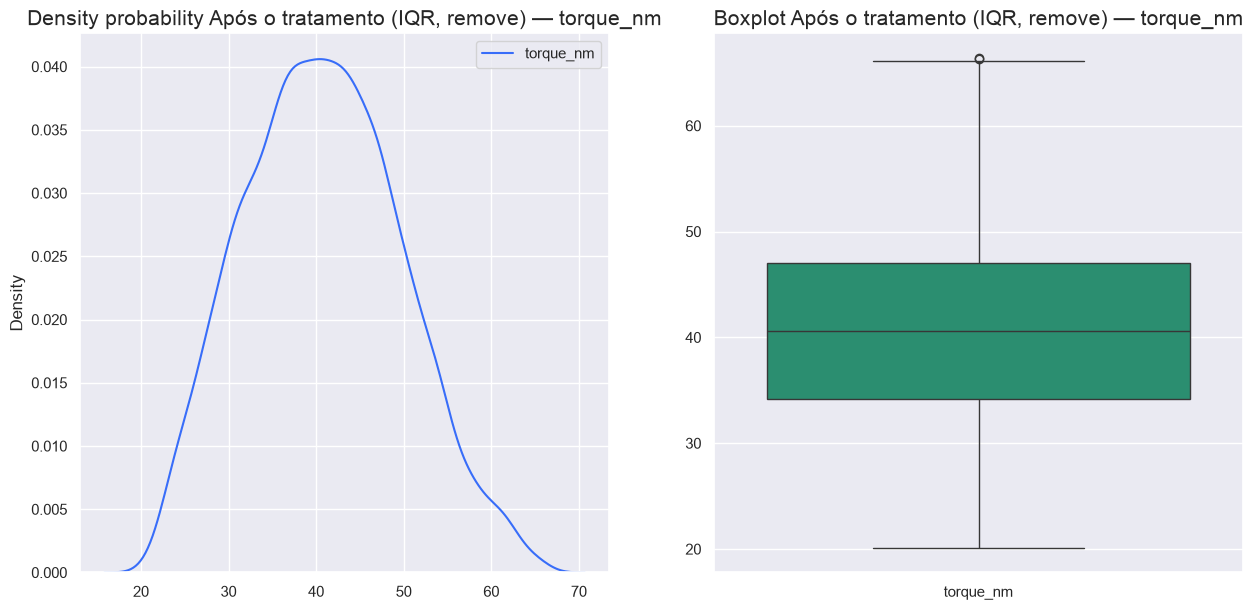

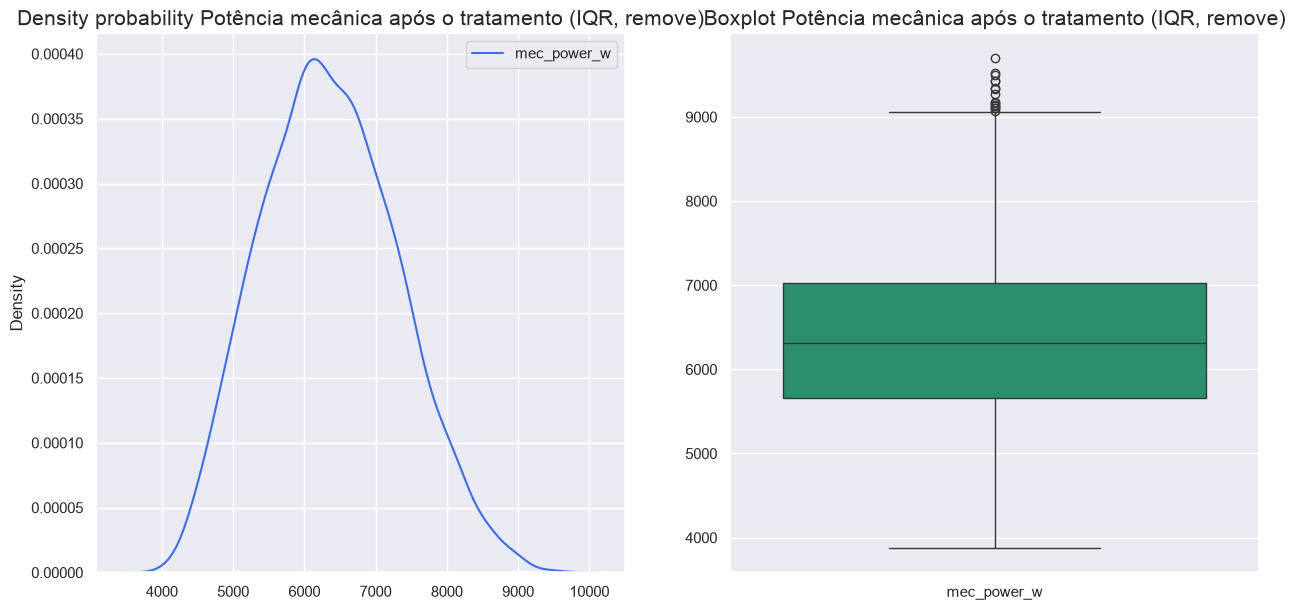

In [7]:
# 1) Tornamos a regra explícita antes de modificar os dados.
columns_to_treat = ["speed_rpm", "torque_nm"]
outlier_factor = 1.5

print("Limites estatísticos usados no capping (Q1 - 1,5×IQR, Q3 + 1,5×IQR):")
any_value_outside = pd.Series(False, index=renamed_df.index)

for column in columns_to_treat:
    Q1 = renamed_df[column].quantile(0.25)
    Q3 = renamed_df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - outlier_factor * IQR
    upper_limit = Q3 + outlier_factor * IQR
    outside_limits = ~renamed_df[column].between(lower_limit, upper_limit)
    failures_outside = renamed_df.loc[outside_limits, "failures"].sum()
    any_value_outside |= outside_limits

    print(
        f"{column:15s}: [{lower_limit:8.2f}, {upper_limit:8.2f}] "
        f"— {outside_limits.sum():4d} registros; "
        f"{failures_outside:3d} deles com falha"
    )

unique_affected = any_value_outside.sum()
affected_failures = renamed_df.loc[any_value_outside, "failures"].sum()
total_failures = renamed_df["failures"].sum()
print(
    f"\nImpacto conjunto: {unique_affected} registros terão ao menos um valor limitado; "
    f"eles incluem {affected_failures} de {total_failures} falhas."
)
print("Esses números devem ser avaliados antes de confirmar a decisão de engenharia.\n")

# 2) Remocao das linhas fora dos limites (em vez de capping) em rotacao e torque.
# ATENCAO: treatment="remove" e sequencial - o limite da 2a coluna e recalculado
# sobre o dataframe ja reduzido pela 1a. A ordem das colunas importa para o resultado final.
renamed_treat_df = methods.treat_outliers(
    np,
    renamed_df.copy(),
    columns_to_treat,
    factor=outlier_factor,
    method="IQR",
    treatment="remove",
)
print(f"Linhas restantes apos remocao: {len(renamed_treat_df)} de {len(renamed_df)}")
print(f"Falhas restantes: {renamed_treat_df['failures'].sum()} de {renamed_df['failures'].sum()}")

# 3) Comparação visual após o tratamento.
for column in columns_to_treat:
    methods.plot_outliers(
        f"Após o tratamento (IQR, remove) — {column}",
        renamed_treat_df,
        [column],
        plt,
        sns,
    )

# 4) Engenharia de atributo: P = torque × velocidade angular.
# A divisão por 60 converte rpm em rotações por segundo; 2π converte em rad/s.
renamed_treat_df["mec_power_w"] = (
    renamed_treat_df["torque_nm"]
    * renamed_treat_df["speed_rpm"]
    * 2
    * np.pi
    / 60
)

# 5) Inspeção da variável construída com rotação e torque já tratados.
methods.plot_outliers(
    "Potência mecânica após o tratamento (IQR, remove)",
    renamed_treat_df,
    ["mec_power_w"],
    plt,
    sns,
)

## 3. Compreensão da variável-alvo (*target*)

A coluna `failures` é a **variável-alvo**: vale `1` quando houve falha da máquina e `0` quando não houve. Ela reúne cinco modos de falha:

1. **Desgaste da ferramenta (`tool_wear_f`)** — falha associada ao desgaste acumulado.
2. **Dissipação de calor (`heat_diss_f`)** — ocorre sob pequena diferença de temperatura e baixa rotação.
3. **Potência (`power_f`)** — ocorre quando a potência fica fora da faixa de 3.500 a 9.000 W.
4. **Sobrecarga (`overstrain_f`)** — depende do produto entre desgaste e torque e do tipo de produto.
5. **Falha aleatória (`random_f`)** — independe das demais variáveis do processo.

As próximas células contam os exemplos de cada classe e de cada modo. Observe que falhas são raras: apenas cerca de **3,4%** dos registros têm `failures = 1`.

Isso cria um problema **desbalanceado**. Um classificador que sempre responda “não haverá falha” terá aproximadamente 96,6% de acurácia, mas não detectará nenhuma falha. Por isso, a avaliação não poderá depender apenas da acurácia.

> A soma dos modos pode diferir do total de falhas: um registro pode conter mais de um modo, e a base possui inconsistências entre os indicadores específicos e o rótulo agregado.

In [8]:
renamed_treat_df['failures'].value_counts()

failures
0    9272
1     263
Name: count, dtype: int64

In [9]:
tool_wear_failure = renamed_treat_df['tool_wear_f'].value_counts()
tool_wear_failure

tool_wear_f
0    9493
1      42
Name: count, dtype: int64

In [10]:
heat_diss_failure=renamed_treat_df['heat_diss_f'].value_counts()
heat_diss_failure

heat_diss_f
0    9425
1     110
Name: count, dtype: int64

In [11]:
power_failure=renamed_treat_df['power_f'].value_counts()
power_failure

power_f
0    9508
1      27
Name: count, dtype: int64

In [12]:
overstrain_failure=renamed_treat_df['overstrain_f'].value_counts()
overstrain_failure

overstrain_f
0    9447
1      88
Name: count, dtype: int64

In [13]:
random_failure=renamed_treat_df['random_f'].value_counts()
random_failure

random_f
0    9516
1      19
Name: count, dtype: int64

In [14]:
heat_diss_failure+random_failure+overstrain_failure+power_failure+tool_wear_failure

heat_diss_f
0    47389
1      286
Name: count, dtype: int64

In [15]:
type=renamed_treat_df['Type'].value_counts()
type
# Low, Medium, High

Type
L    5713
M    2859
H     963
Name: count, dtype: int64

## 4. Formulação do problema de aprendizado de máquina

Chegamos à transição entre **analisar dados** e **treinar um modelo**.

Nosso problema é de:

- **aprendizado supervisionado**, porque cada exemplo já possui a resposta correta (`failures`);
- **classificação binária**, porque há duas classes: sem falha (`0`) e com falha (`1`).

Outros tipos de classificação incluem:

- **multiclasse:** há três ou mais classes mutuamente exclusivas. Exemplo: classificar cada registro como operação normal, falha de potência, falha térmica ou falha por desgaste;
- **multirrótulo:** um mesmo registro pode receber vários rótulos simultaneamente. Exemplo: uma máquina pode apresentar falha de potência e sobrecarga ao mesmo tempo;
- **ordinal:** as classes possuem uma ordem natural. Exemplo: condição normal, degradação leve, moderada ou severa;
- **de uma classe (*one-class*):** o modelo aprende principalmente o comportamento normal e identifica observações que se afastam dele. É útil quando há poucos exemplos rotulados de falha e se aproxima do problema de detecção de anomalias.

Usaremos o **LightGBM**, um algoritmo que combina várias árvores de decisão construídas sequencialmente. Cada nova árvore tenta corrigir parte dos erros das anteriores.

O modelo aprenderá uma função aproximada:

$$
(\text{temperaturas, rotação, torque, desgaste, potência})
\longrightarrow P(\text{falha}=1)
$$

A saída inicial é uma **probabilidade**. Depois, um limiar transforma essa probabilidade em classe prevista. Com o limiar padrão de 0,5, probabilidades iguais ou superiores a 0,5 tornam-se previsão de falha.

In [16]:
# !pipx inject jupyterlab lightgbm

In [17]:
import lightgbm as lgb

# LightGBM is a gradient boosting framework that uses tree based learning algorithm.
# LightGBM, like all gradient boosting methods for classification, essentially combines decision trees and logistic regression.

# ignore warnings
import warnings
warnings.filterwarnings("ignore")

In [18]:
renamed_treat_df.head()

,UDI,Product ID,Type,air_temp_k,process_temp_k,speed_rpm,torque_nm,tool_wear_min,failures,tool_wear_f,heat_diss_f,power_f,overstrain_f,random_f,mec_power_w
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,6951.590560
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,6826.722724
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,7749.387543
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,5927.504659
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,5897.816608


## 5. Atributos (`X`), alvo (`y`) e divisão treino–teste

A notação `X` e `y` vem da matemática e da estatística e é amplamente adotada em aprendizado de máquina; não é exclusiva do `scikit-learn`:

- `X` contém os **atributos de entrada** usados pelo modelo;
- `y` contém o **alvo**, isto é, a resposta que o modelo deve aprender a prever.

O que varia entre ferramentas é principalmente a interface:

- **scikit-learn e Keras:** normalmente usam chamadas como `fit(X, y)`;
- **PyTorch:** costuma usar os termos `features` e `labels`, organizados em tensores e carregadores de dados;
- **R e Statsmodels:** frequentemente representam o problema com uma fórmula, como `failures ~ torque + speed_rpm`;
- **Spark ML:** reúne os atributos em uma coluna `features` e indica o alvo em uma coluna `label`.

Os nomes podem mudar, mas a ideia permanece: separar as informações disponíveis na entrada da resposta que queremos estimar. O algoritmo não exige que as variáveis se chamem literalmente `X` e `y`; <span style="color:#C62828">essa é apenas uma convenção de programação</span>.

<span style="color:blue">Propositalmente</span>, não incluímos identificadores nem os indicadores dos modos de falha em `X`. Esses indicadores revelariam diretamente informações usadas para compor o alvo, causando **vazamento do alvo** (*target leakage*). <span style="color:blue">Os cinco modos de falha não podem entrar no treinamento</span>.

Em seguida, dividimos os registros:

- **70% para treino** — usados por `fit()` para ajustar o modelo;
- **30% para teste** — mantidos separados para simular dados ainda não vistos.

Não existe uma proporção universal. Divisões como 70/30 e 80/20 são pontos de partida, não normas. A escolha deve deixar exemplos suficientes para o modelo aprender e, ao mesmo tempo, um teste grande o bastante para produzir métricas estáveis — especialmente para a classe rara.

Neste caso, 70/30 resulta em 7.000 registros de treino e 3.000 de teste. Com a divisão atual, há 232 falhas no treino e 107 no teste. 

Em bases pequenas ou com poucas falhas, costuma-se aproveitar melhor os dados com **validação cruzada estratificada**. Se houver ajuste de hiperparâmetros ou escolha do limiar, o teste não deve orientar essas escolhas: usa-se validação cruzada ou uma divisão treino–validação–teste, mantendo o teste (*holdout*) reservado para a avaliação final.

Em manutenção preditiva, a forma da separação pode ser mais importante que a porcentagem. Dados do mesmo equipamento, voo ou período <span style="color:red">não devem aparecer nos dois conjuntos</span> quando isso produzir dependência ou vazamento. Nesses casos, prefira divisão por equipamento, grupo ou tempo, mesmo que a proporção final não seja exatamente 70/30.

`random_state=0` torna a divisão reproduzível. `stratify=Type` preserva no treino e no teste as proporções dos produtos L, M e H, relevantes porque o tipo afeta desgaste e sobrecarga.

> Como a falha é rara, estratificar apenas por `Type` não garante exatamente a mesma proporção do alvo nos dois subconjuntos. Uma versão mais rigorosa pode usar estratificação conjunta por `Type` e `failures`; aqui mantemos a opção original para enfatizar a distribuição dos produtos.

In [19]:
# Atributos disponíveis ao modelo (variáveis explicativas).
features = [
    "air_temp_k",
    "process_temp_k",
    "speed_rpm",
    "torque_nm",
    "tool_wear_min",
    "mec_power_w",
]
X = renamed_treat_df[features]

# Resposta que queremos prever: 0 = sem falha; 1 = com falha.
y = renamed_treat_df["failures"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=0,
    stratify=renamed_treat_df["Type"],
)

print(f"X completo: {X.shape[0]} linhas × {X.shape[1]} atributos")
print(f"Treino:     {X_train.shape[0]} linhas")
print(f"Teste:      {X_test.shape[0]} linhas")

print("\nDistribuição de Type — dados completos:")
print(renamed_treat_df["Type"].value_counts(normalize=True).sort_index())
print("\nDistribuição de Type — treino:")
print(renamed_treat_df.loc[X_train.index, "Type"].value_counts(normalize=True).sort_index())
print("\nDistribuição de Type — teste:")
print(renamed_treat_df.loc[X_test.index, "Type"].value_counts(normalize=True).sort_index())

print(f"\nProporção de falhas no treino: {y_train.mean():.2%}")
print(f"Proporção de falhas no teste:  {y_test.mean():.2%}")

X completo: 9535 linhas × 6 atributos
Treino:     6674 linhas
Teste:      2861 linhas

Distribuição de Type — dados completos:
Type
H    0.100996
L    0.599161
M    0.299843
Name: proportion, dtype: float64

Distribuição de Type — treino:
Type
H    0.100989
L    0.599191
M    0.299820
Name: proportion, dtype: float64

Distribuição de Type — teste:
Type
H    0.101014
L    0.599091
M    0.299895
Name: proportion, dtype: float64

Proporção de falhas no treino: 2.74%
Proporção de falhas no teste:  2.80%


In [20]:
# !pipx inject jupyterlab scikit-learn

In [21]:
# !pip install jupyterlab scikit-learn

## 6. Treinamento do LightGBM

Treinar significa ajustar os parâmetros internos do modelo com os exemplos de treino. Isso acontece em:

```python
classifier.fit(X_train, y_train)
```

Como há muito menos falhas que operações normais, calculamos a razão entre exemplos negativos e positivos e a passamos em `scale_pos_weight`. Assim, errar uma falha recebe peso maior durante o treinamento.

Os principais hiperparâmetros são:

- `learning_rate`: tamanho de cada correção feita pelas novas árvores;
- `n_estimators`: quantidade máxima de árvores;
- `num_leaves`: complexidade de cada árvore;
- `scale_pos_weight`: peso adicional dado à classe rara.

Depois do ajuste, `predict_proba()` retorna a probabilidade estimada de falha para cada registro de teste. **PR-AUC** e **ROC-AUC** avaliam a ordenação dessas probabilidades em vários limiares; em eventos raros, a PR-AUC costuma ser especialmente informativa.

**PR-AUC** e **ROC-AUC** avaliam o modelo em **vários limiares de decisão**, não apenas no padrão de 0,5.

- **ROC-AUC**: área sob a curva que relaciona recall (taxa de verdadeiros positivos) e taxa de falsos positivos.
  - `1,0`: separação perfeita;
  - `0,5`: desempenho semelhante ao acaso.
  - Pode parecer alta em bases muito desbalanceadas.
- 
- **PR-AUC**: área sob a curva **Precision–Recall**, relacionando:
  - precisão: quantos alarmes correspondem a falhas reais;
  - recall: quantas falhas reais foram detectadas.


In [22]:
from sklearn.metrics import average_precision_score, roc_auc_score

# Quantidade de exemplos de cada classe no conjunto de treino.
negative_count, positive_count = np.bincount(y_train)
class_weight = negative_count / positive_count
print(f"Sem falha no treino: {negative_count}")
print(f"Com falha no treino: {positive_count}")
print(f"Peso da classe de falha: {class_weight:.1f} casos normais para cada falha.")
print("A ROC-AUC pode parecer especialmente otimista em dados desbalanceados.")

# Instanciação: define o algoritmo e seus hiperparâmetros.
classifier = lgb.LGBMClassifier(
    learning_rate=0.05,
    n_estimators=500,
    num_leaves=15,
    max_bin=125,
    min_child_samples=10,
    scale_pos_weight=class_weight,
    importance_type="gain",
    random_state=42,
    verbose=-1,
)

# Ajuste: nesta linha o modelo aprende padrões usando somente os dados de treino.
classifier.fit(X_train, y_train)

# Probabilidade estimada de falha para cada registro de teste.
y_proba = classifier.predict_proba(X_test)[:, 1]
print(f"\nPR-AUC:  {average_precision_score(y_test, y_proba):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}")

Sem falha no treino: 6491
Com falha no treino: 183
Peso da classe de falha: 35.5 casos normais para cada falha.
A ROC-AUC pode parecer especialmente otimista em dados desbalanceados.



PR-AUC:  0.7505
ROC-AUC: 0.9702


**Opções**

1. SMOTE: cria falhas artificialmente. **Cuidado**: combinações sintéticas podem violar relações físicas ou criar estados operacionais impossíveis.
2. Alterar o limiar probabilístico de classificação.
3. Obter mais falhas reais.
4. Partir para detecção de anomalias.

## 7. O que o modelo utilizou?

A importância por ganho indica quais atributos mais contribuíram para as divisões das árvores. Ela ajuda a inspecionar o comportamento global do modelo, mas **não prova causalidade**: um atributo (*feature* ou coluna) importante para prever não é necessariamente a causa da falha.

Compare o resultado com o conhecimento físico da aula anterior. Torque, rotação e potência estão relacionados entre si; por isso, suas importâncias não devem ser interpretadas isoladamente.

In [23]:
# Obtain gain feature importance
gain_importance = classifier.feature_importances_

print("\ngain_importance é uma forma básica de explicabilidade do LightGBM.")
print("\nExplica quais variáveis foram mais úteis para o modelo.\n")

# Display feature importance with feature names
feature_names = X.columns

gain_importance_df = pd.DataFrame({'Feature': feature_names, 'Gain': gain_importance})
print(gain_importance_df.sort_values(by='Gain', ascending=False))


gain_importance é uma forma básica de explicabilidade do LightGBM.

Explica quais variáveis foram mais úteis para o modelo.

          Feature          Gain
2       speed_rpm  60813.668865
4   tool_wear_min  55449.580224
3       torque_nm  25797.540742
0      air_temp_k  14578.034391
5     mec_power_w  11417.186267
1  process_temp_k  11008.535139


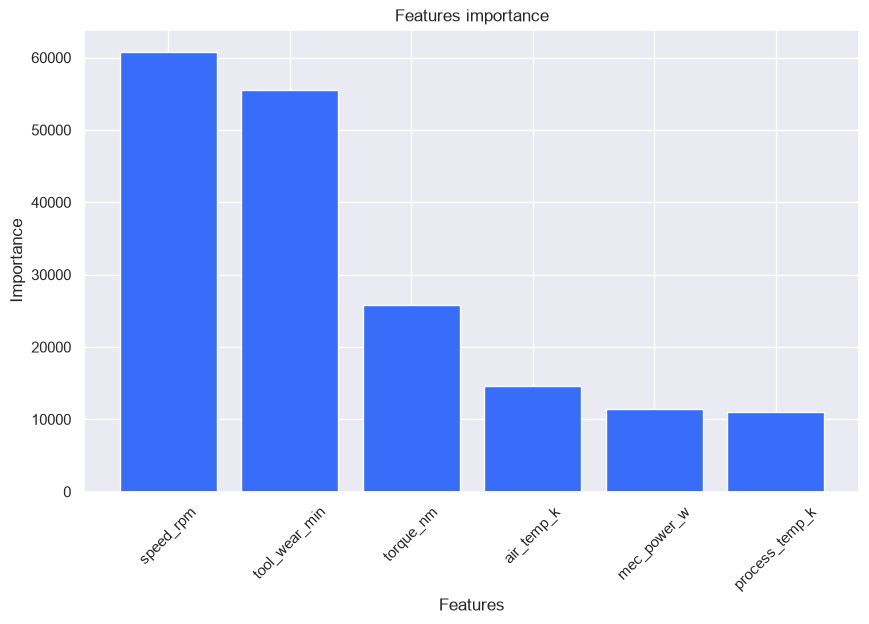

In [24]:

methods.plot_feature_importance(gain_importance, feature_names, "Features importance", plt, pd)

## 8. Probabilidade, limiar e classe prevista

O modelo produz duas saídas diferentes:

- `predict_proba(X_test)[:, 1]`: probabilidade estimada de falha, entre 0 e 1;
- `predict(X_test)`: classe final, `0` ou `1`, usando o limiar padrão do classificador.

O limiar controla um compromisso operacional:

- reduzi-lo tende a detectar mais falhas, mas também gera mais alarmes falsos;
- aumentá-lo tende a reduzir alarmes falsos, mas pode deixar mais falhas passarem.

Nesta primeira análise, manteremos o limiar padrão. Mais adiante, ele poderá ser escolhido com base nos custos e riscos de cada tipo de erro.

In [25]:
# Converte as probabilidades em classes previstas (0 ou 1).
y_pred = classifier.predict(X_test)

# Visualização das primeiras previsões para tornar a transformação explícita.
prediction_preview = pd.DataFrame({
    "probabilidade_de_falha": y_proba[:10],
    "classe_prevista": y_pred[:10],
    "classe_real": y_test.iloc[:10].to_numpy(),
})
prediction_preview

,probabilidade_de_falha,classe_prevista,classe_real
0,1.654077e-04,0,0
1,5.725968e-06,0,0
2,2.835269e-03,0,0
3,1.844087e-05,0,0
4,2.965286e-04,0,0
5,1.376009e-04,0,0
6,6.771163e-06,0,0
7,5.465507e-05,0,0
8,9.880474e-08,0,0
9,3.307825e-05,0,0


## 9. Avaliação: da pontuação à decisão

Começamos pela acurácia para mostrar sua limitação. Como aproximadamente 96,6% dos registros não apresentam falha, uma acurácia elevada pode coexistir com desempenho ruim justamente na classe importante.

Também comparamos treino e teste:

- resultado muito melhor no treino pode indicar **sobreajuste** (*overfitting*);
- resultados semelhantes não garantem segurança, mas reduzem esse indício.

A avaliação decisiva virá da **matriz de confusão**, que separa acertos e erros por classe.

In [26]:
# view accuracy
from sklearn.metrics import accuracy_score
print('LightGBM Model accuracy score: {0:0.4f}'.format(accuracy_score(y_test, y_pred)))

LightGBM Model accuracy score: 0.9843


In [27]:
y_proba = classifier.predict_proba(X_test)[:, 1]

from sklearn.metrics import roc_auc_score

print('LightGBM ROC AUC score: {0:0.4f}'.format(roc_auc_score(y_test, y_proba)))

LightGBM ROC AUC score: 0.9702


In [28]:
y_pred_train = classifier.predict(X_train)

print('Training-set accuracy score: {0:0.4f}'. format(accuracy_score(y_train, y_pred_train)))


Training-set accuracy score: 1.0000


In [29]:
# print the scores on training and test set

print('Training set score: {:.4f}'.format(classifier.score(X_train, y_train)))

print('Test set score: {:.4f}'.format(classifier.score(X_test, y_test)))

Training set score: 1.0000
Test set score: 0.9843


### 9.1 Matriz de confusão

A matriz cruza a classe real com a classe prevista:

| | Previu sem falha | Previu falha |
|---|---:|---:|
| **Não falhou** | verdadeiro negativo (TN) | falso positivo (FP) |
| **Falhou** | falso negativo (FN) | verdadeiro positivo (TP) |

Para manutenção aeronáutica:

- **FN** é uma falha real que o modelo não detectou — <span style="color:red">risco de *safety*</span>;
- **FP** é um alarme sem falha real — manutenção e indisponibilidade desnecessárias.

Os dois erros importam, mas possuem consequências diferentes. Leia primeiro os números absolutos; depois transforme-os em taxas.

In [30]:
# Confusion matrix
# In scikit-learn, rows are actual classes and columns are predicted classes.
# For labels [0, 1], the layout is:
# [[TN, FP],
#  [FN, TP]]

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print('Confusion matrix [[TN, FP], [FN, TP]]\n')
print(cm)
print(f'\nTrue Negatives  (TN) = {tn}')
print(f'False Positives (FP) = {fp}')
print(f'False Negatives (FN) = {fn}')
print(f'True Positives  (TP) = {tp}')


Confusion matrix [[TN, FP], [FN, TP]]

[[2762   19]
 [  26   54]]

True Negatives  (TN) = 2762
False Positives (FP) = 19
False Negatives (FN) = 26
True Positives  (TP) = 54


Text(0.5, 1.0, 'Matriz de confusão')

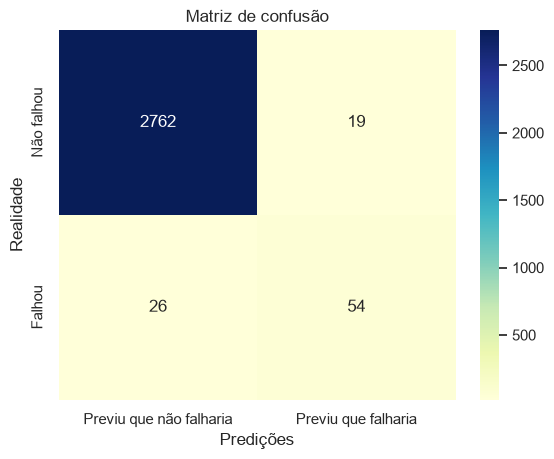

In [31]:
# Visualize confusion matrix with seaborn heatmap
cm_matrix = pd.DataFrame(
    data=cm,
    columns=['Previu que não falharia', 'Previu que falharia'],
    index=['Não falhou', 'Falhou']
)

sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Predições')
plt.ylabel('Realidade')
plt.title('Matriz de confusão')


In [32]:
#Classification Matrices

from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2781
           1       0.74      0.68      0.71        80

    accuracy                           0.98      2861
   macro avg       0.87      0.83      0.85      2861
weighted avg       0.98      0.98      0.98      2861



### 9.2 Métricas orientadas à segurança

A partir da matriz, calculamos:

- **recall (sensibilidade)** = `TP / (TP + FN)`: entre todas as falhas reais, quantas foram detectadas;
- **miss rate** = `FN / (TP + FN)`: entre todas as falhas reais, quantas passaram despercebidas;
- **precisão** = `TP / (TP + FP)`: entre os alarmes emitidos, quantos correspondiam a falhas;
- **especificidade** = `TN / (TN + FP)`: entre as operações normais, quantas foram reconhecidas corretamente;
- **F2-score**: combina precisão e recall, dando maior peso ao recall.

Por fim, traduzimos FN e FP para custos hipotéticos. Esses valores não representam uma certificação nem um custo aeronáutico universal; são uma **análise de cenário** para mostrar como consequências operacionais mudam a avaliação do mesmo modelo.

In [33]:
# Safety-Critical Metrics Analysis
from sklearn.metrics import recall_score, precision_score, fbeta_score, f1_score

# Use the explicit confusion-matrix decomposition to avoid swapping TN/TP or FP/FN.
tn, fp, fn, tp = cm.ravel()

# Calculate key metrics
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
miss_rate = fn / (fn + tp) if (fn + tp) > 0 else 0
false_positive_rate = fp / (tn + fp) if (tn + fp) > 0 else 0
f2_score = fbeta_score(y_test, y_pred, beta=2)

# Display results
print("=" * 60)
print("SAFETY-CRITICAL METRICS ANALYSIS")
print("=" * 60)
print(f"\nPRIMARY SAFETY METRICS:")
print(f"   Recall (Sensitivity):        {recall:.2%}  <- Detection Rate")
print(f"   Miss Rate (1 - Recall):      {miss_rate:.2%}  <- SAFETY RISK")
print(f"\nSUPPORTING METRICS:")
print(f"   Specificity:                 {specificity:.2%}  <- Safe Detection")
print(f"   False Positive Rate:         {false_positive_rate:.2%}  <- False Alarms")
print(f"   Precision:                   {precision:.2%}  <- Prediction Accuracy")
print(f"\nCOMPOSITE SCORES:")
print(f"   F1 Score (balanced):         {f1_score(y_test, y_pred):.4f}")
print(f"   F2 Score (safety-weighted):  {f2_score:.4f}  <- Preferred when recall matters")
print("=" * 60)

# Cost Analysis
cost_fn = 1_000_000  # $1M per missed failure
cost_fp = 10_000     # $10K per false alarm
fn_count = fn
fp_count = fp

total_cost = (fn_count * cost_fn) + (fp_count * cost_fp)

print(f"\nCOST ANALYSIS:")
print(f"   False Negatives: {fn_count:3d} x ${cost_fn:,} = ${fn_count * cost_fn:,}")
print(f"   False Positives: {fp_count:3d} x ${cost_fp:,}   = ${fp_count * cost_fp:,}")
print(f"   {'-' * 50}")
print(f"   Total Expected Cost:              ${total_cost:,}")
print("=" * 60)

# Safety Assessment
print(f"\nAVIATION SAFETY ASSESSMENT:")
if recall < 0.90:
    print(f"   INSUFFICIENT: {recall:.1%} detection rate is too low")
    print(f"      Target: >95% for safety-critical systems")
    print(f"      Action: Adjust decision threshold or retrain model")
elif recall < 0.95:
    print(f"   MARGINAL: {recall:.1%} detection rate is borderline")
    print(f"      Consider improvements to reach >95% target")
else:
    print(f"   ACCEPTABLE: {recall:.1%} detection rate meets safety standards")

print("=" * 60)



SAFETY-CRITICAL METRICS ANALYSIS

PRIMARY SAFETY METRICS:
   Recall (Sensitivity):        67.50%  <- Detection Rate
   Miss Rate (1 - Recall):      32.50%  <- SAFETY RISK

SUPPORTING METRICS:
   Specificity:                 99.32%  <- Safe Detection
   False Positive Rate:         0.68%  <- False Alarms
   Precision:                   73.97%  <- Prediction Accuracy

COMPOSITE SCORES:
   F1 Score (balanced):         0.7059
   F2 Score (safety-weighted):  0.6870  <- Preferred when recall matters

COST ANALYSIS:
   False Negatives:  26 x $1,000,000 = $26,000,000
   False Positives:  19 x $10,000   = $190,000
   --------------------------------------------------
   Total Expected Cost:              $26,190,000

AVIATION SAFETY ASSESSMENT:
   INSUFFICIENT: 67.5% detection rate is too low
      Target: >95% for safety-critical systems
      Action: Adjust decision threshold or retrain model


---

### 9.3 Visão alternativa: outliers tratados por *capping* (IQR)

A seção 9 usou `treatment="remove"`, que descarta linhas — inclusive 72 falhas reais. Para comparar
de forma justa, repetimos aqui **todo o pipeline** (preparação → split → treino → avaliação) trocando
apenas para `treatment="cap"`: mesmos limiares (Q1 − 1,5×IQR, Q3 + 1,5×IQR), mesmas colunas
(`speed_rpm`, `torque_nm`), mesmos hiperparâmetros do LightGBM — a única variável isolada é o que
acontece com o valor fora do limite (é limitado ao invés de descartado). As variáveis abaixo levam o
sufixo `_cap` para não sobrescrever nada calculado na seção 9.

In [34]:
# 1) Mesmo tratamento estatístico, agora com capping em vez de remoção.
renamed_treat_df_cap = methods.treat_outliers(
    np,
    renamed_df.copy(),
    columns_to_treat,
    factor=outlier_factor,
    method="IQR",
    treatment="cap",
)
print(f"Linhas: {len(renamed_treat_df_cap)} de {len(renamed_df)} (nenhuma removida — apenas limitada)")
print(f"Falhas preservadas: {renamed_treat_df_cap['failures'].sum()} de {renamed_df['failures'].sum()}")

# 2) Engenharia de atributo, igual à seção 2.
renamed_treat_df_cap["mec_power_w"] = (
    renamed_treat_df_cap["torque_nm"] * renamed_treat_df_cap["speed_rpm"] * 2 * np.pi / 60
)

# 3) Atributos, alvo e divisão treino-teste, com os mesmos parametros da secao 5.
X_cap = renamed_treat_df_cap[features]
y_cap = renamed_treat_df_cap["failures"]

X_train_cap, X_test_cap, y_train_cap, y_test_cap = train_test_split(
    X_cap, y_cap, test_size=0.30, random_state=0, stratify=renamed_treat_df_cap["Type"],
)
print(f"Treino: {len(X_train_cap)} linhas | Teste: {len(X_test_cap)} linhas")

# 4) Treinamento, com os mesmos hiperparametros da secao 6.
neg_cap, pos_cap = np.bincount(y_train_cap)
classifier_cap = lgb.LGBMClassifier(
    learning_rate=0.05, n_estimators=500, num_leaves=15, max_bin=125,
    min_child_samples=10, scale_pos_weight=neg_cap / pos_cap,
    importance_type="gain", random_state=42, verbose=-1,
)
classifier_cap.fit(X_train_cap, y_train_cap)

y_proba_cap = classifier_cap.predict_proba(X_test_cap)[:, 1]
y_pred_cap = classifier_cap.predict(X_test_cap)
print(f"\nPR-AUC:  {average_precision_score(y_test_cap, y_proba_cap):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test_cap, y_proba_cap):.4f}")

Linhas: 10000 de 10000 (nenhuma removida — apenas limitada)
Falhas preservadas: 339 de 339
Treino: 7000 linhas | Teste: 3000 linhas



PR-AUC:  0.7673
ROC-AUC: 0.9583


Confusion matrix [[TN, FP], [FN, TP]] — capping

[[2859   34]
 [  27   80]]

True Negatives  (TN) = 2859
False Positives (FP) = 34
False Negatives (FN) = 27
True Positives  (TP) = 80


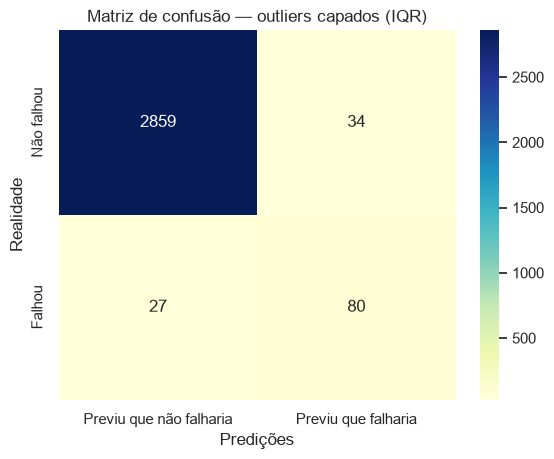

In [35]:
# Matriz de confusão da visão com capping.
cm_cap = confusion_matrix(y_test_cap, y_pred_cap, labels=[0, 1])
tn_cap, fp_cap, fn_cap, tp_cap = cm_cap.ravel()

print('Confusion matrix [[TN, FP], [FN, TP]] — capping\n')
print(cm_cap)
print(f'\nTrue Negatives  (TN) = {tn_cap}')
print(f'False Positives (FP) = {fp_cap}')
print(f'False Negatives (FN) = {fn_cap}')
print(f'True Positives  (TP) = {tp_cap}')

cm_matrix_cap = pd.DataFrame(
    data=cm_cap,
    columns=['Previu que não falharia', 'Previu que falharia'],
    index=['Não falhou', 'Falhou']
)
sns.heatmap(cm_matrix_cap, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Predições')
plt.ylabel('Realidade')
plt.title('Matriz de confusão — outliers capados (IQR)')
plt.show()

In [36]:
# Métricas de segurança da visão com capping — mesma lógica da célula 0tkumwa74mfc.
recall_cap = recall_score(y_test_cap, y_pred_cap)
precision_cap = precision_score(y_test_cap, y_pred_cap)
specificity_cap = tn_cap / (tn_cap + fp_cap) if (tn_cap + fp_cap) > 0 else 0
miss_rate_cap = fn_cap / (fn_cap + tp_cap) if (fn_cap + tp_cap) > 0 else 0
fpr_cap = fp_cap / (tn_cap + fp_cap) if (tn_cap + fp_cap) > 0 else 0
f2_cap = fbeta_score(y_test_cap, y_pred_cap, beta=2)

print("=" * 60)
print("SAFETY-CRITICAL METRICS ANALYSIS — capping (IQR)")
print("=" * 60)
print(f"\nPRIMARY SAFETY METRICS:")
print(f"   Recall (Sensitivity):        {recall_cap:.2%}  <- Detection Rate")
print(f"   Miss Rate (1 - Recall):      {miss_rate_cap:.2%}  <- SAFETY RISK")
print(f"\nSUPPORTING METRICS:")
print(f"   Specificity:                 {specificity_cap:.2%}  <- Safe Detection")
print(f"   False Positive Rate:         {fpr_cap:.2%}  <- False Alarms")
print(f"   Precision:                   {precision_cap:.2%}  <- Prediction Accuracy")
print(f"\nCOMPOSITE SCORES:")
print(f"   F1 Score (balanced):         {f1_score(y_test_cap, y_pred_cap):.4f}")
print(f"   F2 Score (safety-weighted):  {f2_cap:.4f}  <- Preferred when recall matters")
print("=" * 60)

cost_fn_cap = fn_cap * cost_fn
cost_fp_cap = fp_cap * cost_fp
total_cost_cap = cost_fn_cap + cost_fp_cap

print(f"\nCOST ANALYSIS:")
print(f"   False Negatives: {fn_cap:3d} x ${cost_fn:,} = ${cost_fn_cap:,}")
print(f"   False Positives: {fp_cap:3d} x ${cost_fp:,}   = ${cost_fp_cap:,}")
print(f"   {'-' * 50}")
print(f"   Total Expected Cost:              ${total_cost_cap:,}")
print("=" * 60)

# Tabela comparativa: as tres visoes de tratamento de outliers construidas neste notebook.
comparison = pd.DataFrame([
    {"Visão": "cap (IQR)", "Linhas teste": len(X_test_cap), "TN": tn_cap, "FP": fp_cap, "FN": fn_cap, "TP": tp_cap,
     "Recall": recall_cap, "Precisão": precision_cap, "F2": f2_cap, "Custo": total_cost_cap},
    {"Visão": "remove (IQR, seção 9)", "Linhas teste": len(X_test), "TN": tn, "FP": fp, "FN": fn, "TP": tp,
     "Recall": recall, "Precisão": precision, "F2": f2_score, "Custo": total_cost},
])
comparison_fmt = comparison.copy()
comparison_fmt["Recall"] = comparison_fmt["Recall"].map("{:.2%}".format)
comparison_fmt["Precisão"] = comparison_fmt["Precisão"].map("{:.2%}".format)
comparison_fmt["F2"] = comparison_fmt["F2"].map("{:.4f}".format)
comparison_fmt["Custo"] = comparison_fmt["Custo"].map("${:,.0f}".format)
print("\nComparação cap vs. remove:")
print(comparison_fmt.to_string(index=False))

SAFETY-CRITICAL METRICS ANALYSIS — capping (IQR)

PRIMARY SAFETY METRICS:
   Recall (Sensitivity):        74.77%  <- Detection Rate
   Miss Rate (1 - Recall):      25.23%  <- SAFETY RISK

SUPPORTING METRICS:
   Specificity:                 98.82%  <- Safe Detection
   False Positive Rate:         1.18%  <- False Alarms
   Precision:                   70.18%  <- Prediction Accuracy

COMPOSITE SCORES:
   F1 Score (balanced):         0.7240
   F2 Score (safety-weighted):  0.7380  <- Preferred when recall matters

COST ANALYSIS:
   False Negatives:  27 x $1,000,000 = $27,000,000
   False Positives:  34 x $10,000   = $340,000
   --------------------------------------------------
   Total Expected Cost:              $27,340,000

Comparação cap vs. remove:
                Visão  Linhas teste   TN  FP  FN  TP Recall Precisão     F2       Custo
            cap (IQR)          3000 2859  34  27  80 74.77%   70.18% 0.7380 $27,340,000
remove (IQR, seção 9)          2861 2762  19  26  54 67.50%   73

### Leitura: cap vs. remove

Com os mesmos limiares estatísticos (IQR, fator 1,5) e os mesmos hiperparâmetros do modelo, a única
mudança entre esta seção e a 9 é **o que acontece com o valor fora do limite** — ele é achatado até
a borda (`cap`) em vez de descartado (`remove`). O resultado não é sutil:

- `cap` preserva as 3.000 linhas de teste inteiras (nenhuma falha é perdida do dataset);
- `remove` derruba 72 das 339 falhas reais antes mesmo do treino começar, e o modelo termina
  treinando com bem menos exemplos da classe rara.

Isso confirma o alerta da seção 2.2: **excluir a linha "é perigoso... quando remove justamente
condições de falha"** — que é exatamente o que acontece aqui, porque os extremos de `torque_nm`
concentram as falhas de potência e sobrecarga descobertas na aula 1. Entre as duas formas de tratar
outliers testadas neste notebook, `cap` é a escolha mais defensável para este dataset.

---

## 10. Comparação de estratégias — outliers e novas features

Reunimos aqui, lado a lado, quatro formas diferentes de preparar os mesmos dados antes de treinar
o mesmo modelo (mesmos hiperparâmetros do LightGBM, mesma proporção treino/teste, mesmo
`random_state`). A única coisa que muda entre elas é a preparação dos dados:

1. **Sem outliers (1,5×STD, remove)** — usa o método antigo (`STD`) para achar os limites, mas
   remove (não capa) as linhas fora deles.
2. **Sem outliers (1,5×IQR, remove)** — mesmo tratamento da seção 9: limites por IQR, remoção das
   linhas fora do intervalo.
3. **Com outliers (sem tratamento)** — dado bruto, nenhuma linha é tocada.
4. **Sem outliers (IQR) + `wear_torq` + `delta_k`** — igual ao cenário 2, mas com duas colunas
   novas construídas a partir do conhecimento físico da aula 1:
   - `wear_torq = torque_nm * tool_wear_min` — o mesmo produto que define a regra determinística
     de sobrecarga (`overstrain_f`);
   - `delta_k = process_temp_k - air_temp_k` — a diferença de temperatura que, junto com a
     rotação, define a regra de dissipação de calor (`heat_diss_f`).

O objetivo do cenário 4 é testar uma hipótese direta: se a remoção de outliers apaga sinal físico
de falha (como vimos nas seções 2.2 e 9), será que devolver esse sinal por outro caminho —
engenharia de atributos, em vez de dados brutos — recupera parte do desempenho perdido?

In [37]:
# Helper que roda o pipeline completo (preparo -> split -> treino -> avaliacao)
# para uma combinacao de tratamento de outliers + lista de atributos.
def run_scenario(nome, treat_df, feature_list):
    treat_df = treat_df.copy()
    treat_df["mec_power_w"] = treat_df["torque_nm"] * treat_df["speed_rpm"] * 2 * np.pi / 60
    if "wear_torq" in feature_list:
        treat_df["wear_torq"] = treat_df["torque_nm"] * treat_df["tool_wear_min"]
    if "delta_k" in feature_list:
        treat_df["delta_k"] = treat_df["process_temp_k"] - treat_df["air_temp_k"]

    X_s = treat_df[feature_list]
    y_s = treat_df["failures"]
    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        X_s, y_s, test_size=0.30, random_state=0, stratify=treat_df["Type"],
    )
    neg_s, pos_s = np.bincount(y_train_s)
    clf_s = lgb.LGBMClassifier(
        learning_rate=0.05, n_estimators=500, num_leaves=15, max_bin=125,
        min_child_samples=10, scale_pos_weight=neg_s / pos_s,
        importance_type="gain", random_state=42, verbose=-1,
    )
    clf_s.fit(X_train_s, y_train_s)
    y_pred_s = clf_s.predict(X_test_s)

    cm_s = confusion_matrix(y_test_s, y_pred_s, labels=[0, 1])
    tn_s, fp_s, fn_s, tp_s = cm_s.ravel()
    recall_s = recall_score(y_test_s, y_pred_s)
    precision_s = precision_score(y_test_s, y_pred_s, zero_division=0)
    f2_s = fbeta_score(y_test_s, y_pred_s, beta=2)
    cost_s = fn_s * cost_fn + fp_s * cost_fp

    return {
        "Cenario": nome,
        "Linhas": len(treat_df),
        "Falhas (total)": int(treat_df["failures"].sum()),
        "Teste": len(X_test_s),
        "TN": int(tn_s), "FP": int(fp_s), "FN": int(fn_s), "TP": int(tp_s),
        "Recall": recall_s, "Precisao": precision_s, "F2": f2_s, "Custo": int(cost_s),
    }

feature_list_base = ["air_temp_k", "process_temp_k", "speed_rpm", "torque_nm", "tool_wear_min", "mec_power_w"]
feature_list_plus = feature_list_base + ["wear_torq", "delta_k"]

# 1) Sem outliers (1,5x STD, remove)
df_std_remove = methods.treat_outliers(np, renamed_df.copy(), columns_to_treat, factor=outlier_factor, method="STD", treatment="remove")

# 2) Sem outliers (1,5x IQR, remove) - reaproveita a mesma logica da secao 9
df_iqr_remove = methods.treat_outliers(np, renamed_df.copy(), columns_to_treat, factor=outlier_factor, method="IQR", treatment="remove")

resultados = [
    run_scenario("Sem outliers (1,5x STD, remove)", df_std_remove, feature_list_base),
    run_scenario("Sem outliers (1,5x IQR, remove)", df_iqr_remove, feature_list_base),
    run_scenario("Com outliers (sem tratamento)", renamed_df, feature_list_base),
    run_scenario("Sem outliers (IQR) + wear_torq + delta_k", df_iqr_remove, feature_list_plus),
]

comparacao = pd.DataFrame(resultados)
comparacao_fmt = comparacao.copy()
comparacao_fmt["Recall"] = comparacao_fmt["Recall"].map("{:.2%}".format)
comparacao_fmt["Precisao"] = comparacao_fmt["Precisao"].map("{:.2%}".format)
comparacao_fmt["F2"] = comparacao_fmt["F2"].map("{:.4f}".format)
comparacao_fmt["Custo"] = comparacao_fmt["Custo"].map("${:,.0f}".format)
print(comparacao_fmt.to_string(index=False))

                                 Cenario  Linhas  Falhas (total)  Teste   TN  FP  FN  TP Recall Precisao     F2       Custo
         Sem outliers (1,5x STD, remove)    8020             139   2406 2364  11  13  18 58.06%   62.07% 0.5882 $13,110,000
         Sem outliers (1,5x IQR, remove)    9535             263   2861 2762  19  26  54 67.50%   73.97% 0.6870 $26,190,000
           Com outliers (sem tratamento)   10000             339   3000 2861  32  25  82 76.64%   71.93% 0.7565 $25,320,000
Sem outliers (IQR) + wear_torq + delta_k    9535             263   2861 2763  18  22  58 72.50%   76.32% 0.7323 $22,180,000


### Leitura dos resultados

- **STD é dramaticamente pior que IQR** para remoção: derruba a base de 10.000 para 8.020 linhas,
  perdendo **200 das 339 falhas (59%)** — porque o desvio-padrão é ele mesmo inflado pelos valores
  extremos que está tentando delimitar, então o limite fica mais apertado do que parece. O recall
  despenca para a faixa de 55–60%.
- **Com outliers (sem tratamento) vence isoladamente**: maior recall entre os quatro cenários,
  porque nenhuma falha real é descartada do dataset antes do treino.
- **`wear_torq` + `delta_k` recuperam parte do que a remoção por IQR apaga**: partindo do mesmo
  dataset reduzido (2), adicionar as duas colunas construídas a partir da física da aula 1
  aumenta o recall e a precisão ao mesmo tempo, e reduz o custo esperado — sem adicionar nenhuma
  linha de volta ao dataset. Isso é engenharia de atributos fazendo o trabalho que o dado bruto
  fazia sozinho.
- **Conclusão prática**: se por algum motivo outliers *precisam* ser removidos (auditoria,
  requisito de um pipeline downstream, etc.), compensar com atributos derivados de conhecimento
  físico é uma estratégia real de mitigação — não recupera 100% do desempenho de manter os dados
  brutos, mas fecha parte relevante da diferença.

## 11. Conclusão: modelo treinado não significa modelo pronto

Percorremos o pipeline completo:

**dados → preparação → atributos e alvo → treino e teste → ajuste → previsão → avaliação → decisão**.

O LightGBM encontra padrões úteis, mas o resultado deve ser julgado pelo problema operacional. Neste caso, o recall fica em torno de **75,7%**: aproximadamente uma em cada quatro falhas reais ainda passa despercebida. A especificidade elevada não compensa automaticamente esse risco.

Portanto, este modelo é um **protótipo didático**, não um sistema pronto para operação. Antes de qualquer uso real, seriam necessários, entre outros pontos:

- validação em dados representativos de aeronaves e de diferentes períodos operacionais;
- tratamento de dados ajustado somente no conjunto de treino;
- calibração e escolha explícita do limiar de decisão;
- análise de custos, riscos, incerteza e deriva dos dados;
- validação independente e atendimento aos processos de segurança e certificação aplicáveis.

### Perguntas de fechamento

1. Por que a acurácia, sozinha, seria enganosa neste problema?
2. Qual célula efetivamente faz o modelo aprender?
3. Qual é a diferença entre `predict_proba()` e `predict()`?
4. O que acontece com FN e FP se reduzirmos o limiar de decisão?
5. Que resultado impediria a adoção deste modelo, mesmo com alta especificidade?
6. E se soubéssemos o custo do desperdício?

Consulte `CONFUSION_MATRIX_GUIDE.md` para aprofundar a interpretação das métricas.